<a href="https://colab.research.google.com/github/TreesaAbraham/svd-image-compression-MATH344L/blob/main/notebook/02_svd_approximation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Milestone 2: The SVD and Rank-k Approximation

In [2]:
#load the image
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
A = data.camera().astype(float)
print(A.shape, A.dtype)

(512, 512) float64


In [3]:
# Compute and check the SVD
#splits the matrix into U(512x512) with orthonormal columns, s an array of 512 numbers, and Vt the transpose of U
#A_back multiples the pieces back together, and the prints confirm if it was built and the largest error

U, s, Vt = np.linalg.svd(A, full_matrices=False)
print("U:", U.shape, "s:", s.shape, "Vt:", Vt.shape)

A_back = U @ np.diag(s) @ Vt
print("Rebuilt correctly?", np.allclose(A, A_back))
print("Largest error:", np.abs(A - A_back).max())

U: (512, 512) s: (512,) Vt: (512, 512)
Rebuilt correctly? True
Largest error: 2.538058652135078e-11


First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


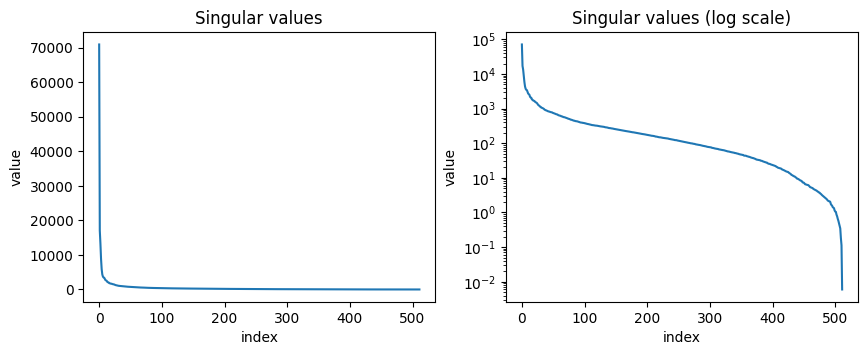

In [11]:
# Inspect the singular values
#print the largest singular values, then print the 50th, 200th, and last values
print("First five:", np.round(s[:5], 1))
print("50th, 200th, last:", round(s[49], 1),
round(s[199], 1), round(s[-1], 3))
#axl1 plots the values on a regular linear axis, Fast decay show low-rank approximation A_k works well
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(s)
ax1.set(title="Singular values", xlabel="index", ylabel="value")
#axl2 plots the points on a log scale, steep drop (main structure/brightness), long slope (fine details), last value (0.006)->large drop
ax2.semilogy(s)
ax2.set(title="Singular values (log scale)", xlabel="index", ylabel="value")
plt.show()

In [12]:
# Make a rank-k approximation
def rank_k_approx(A, k):
  # Return the rank-k SVD approximation of A. U: a matrix with left singlular vectors, s: 1-d array of singluar values, Vt: V transpose
  U, s, Vt = np.linalg.svd(A, full_matrices=False)


In [6]:
print("rank of A_10:", np.linalg.matrix_rank(rank_k_approx(A, 10)))
print("k = 512 gives A back?", np.allclose(rank_k_approx(A, 512), A))
stripes = np.outer([1, 0, 1, 0], [1, 1, 1, 1]).astype(float)
print("singular values of stripes:", np.round(np.linalg.svd(stripes, compute_uv=False), 4))

rank of A_10: 10
k = 512 gives A back? True
singular values of stripes: [2.8284 0.     0.     0.    ]


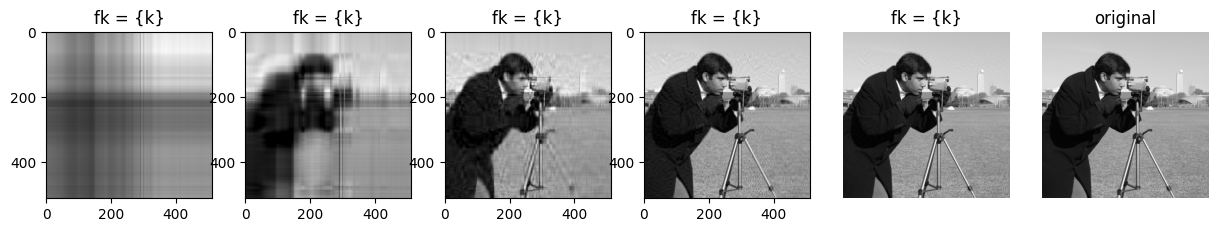

In [7]:
# Compare compressed images
ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
for ax, k in zip(axes, ks):
  Ak = np.clip(rank_k_approx(A, k), 0, 255)
  ax.imshow(Ak, cmap="gray", vmin=0, vmax=255)
  ax.set_title("fk = {k}")
ax.axis("off")
axes[-1].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("original")
axes[-1].axis("off")
plt.show()